# 🔮 CRAZY AI LOTTO TRANSFORMER V1.1 (Integrated Colab)

**한 파일 통합본**  
- 데이터 수집 → 전처리 → Transformer 학습 (여러 Lookback 비교) → 평가 → 다음 회차 예측  
- Streamlit 대시보드 + Cloudflare Tunnel 공개 URL 자동 생성  

**실행 순서**  
1. Runtime → Change runtime type → GPU (T4 권장)  
2. 위에서부터 순서대로 셀 실행  
3. 마지막 Streamlit 셀 실행 후 출력되는 `https://xxxx.trycloudflare.com` 주소로 접속  

> 주의: 로또 번호 예측은 통계적 실험 목적이며, 실제 당첨을 보장하지 않습니다.

In [ ]:
!pip -q install requests pandas numpy scikit-learn matplotlib tqdm streamlit

In [ ]:
import os
import json
import time
import random
import itertools
import copy
import warnings
import re
import subprocess

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from collections import Counter

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import log_loss

warnings.filterwarnings("ignore")

# ============================================================
# CRAZY AI LOTTO TRANSFORMER V1.1
# Reproducibility and device configuration
# ============================================================

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

In [ ]:
# ============================================================
# PROJECT CONFIGURATION
# ============================================================

PROJECT_NAME = "CRAZY_AI_LOTTO_TRANSFORMER_V1_1"

OUTPUT_DIR = f"/content/{PROJECT_NAME}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

NUM_NUMBERS = 45
NUM_WINNING_NUMBERS = 6

# Dynamic adjustment of lookback windows to prevent empty splits
TOTAL_ROUNDS = len(df) if 'df' in globals() else 1248

# Safe lookback threshold for validation partition
MAX_SAFE_LOOKBACK = TOTAL_ROUNDS

# Include specific standard lookbacks, explicitly appending 1248 (TOTAL_ROUNDS) to represent the entire history.
LOOKBACK_LIST = [10, 30, 50, 100, 200, 500, 1000, 1198, TOTAL_ROUNDS]
LOOKBACK_LIST = sorted(list(set([L for L in LOOKBACK_LIST if L <= TOTAL_ROUNDS])))

# Main architecture
D_MODEL = 128
N_HEADS = 8
NUM_ENCODER_LAYERS = 6
DIM_FF = 256
DROPOUT = 0.10

# Training
BATCH_SIZE = 32
EPOCHS = 1500
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 500

# Common chronological evaluation range uses maximum lookback that allows validation (1198) for training/eval validation integrity
MAX_LOOKBACK = 1198

print("Project:", PROJECT_NAME)
print("Entire History Lookback Option:", TOTAL_ROUNDS)
print("Adjusted Lookbacks:", LOOKBACK_LIST)
print("Attention Heads:", N_HEADS)
print("Encoder Layers:", NUM_ENCODER_LAYERS)
print("Head Dimension:", D_MODEL // N_HEADS)

In [ ]:
# ============================================================
# LOTTO 6/45 DATA COLLECTOR
# ============================================================

BASE_URL = "https://www.dhlottery.co.kr/lt645"

LATEST_URL = (
    f"{BASE_URL}/selectPstLt645Info.do"
)

ROUND_URL = (
    f"{BASE_URL}/selectPstLt645InfoNew.do"
)

HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 Chrome/120.0 Safari/537.36"
    ),
    "Accept": "application/json, text/plain, */*",
    "X-Requested-With": "XMLHttpRequest",
    "Referer": "https://www.dhlottery.co.kr/"
}

SESSION = requests.Session()
SESSION.headers.update(HEADERS)


def extract_records(obj):
    """
    Recursively locate a list of lottery draw records.
    """

    if isinstance(obj, list):
        if obj and isinstance(obj[0], dict):
            if (
                "ltEpsd" in obj[0]
                or "tm1WnNo" in obj[0]
            ):
                return obj

        for item in obj:
            result = extract_records(item)
            if result:
                return result

    elif isinstance(obj, dict):
        for value in obj.values():
            result = extract_records(value)
            if result:
                return result

    return []


def request_json(url, params=None, retries=3):
    """
    Request JSON with retry and response validation.
    """

    last_error = None

    for attempt in range(retries):
        try:
            response = SESSION.get(
                url,
                params=params,
                timeout=20
            )

            response.raise_for_status()

            data = response.json()

            if not isinstance(data, (dict, list)):
                raise ValueError("Unexpected API response type")

            return data

        except Exception as exc:
            last_error = exc
            time.sleep(1.5 * (attempt + 1))

    raise RuntimeError(
        f"API request failed: {url}\n{last_error}"
    )


def normalize_record(item):
    """
    Convert the current API field names into a
    consistent internal record.
    """

    draw_no = int(item["ltEpsd"])

    numbers = [
        int(item[f"tm{i}WnNo"])
        for i in range(1, 7)
    ]

    bonus = int(item["bnsWnNo"])

    draw_date = str(item.get("ltRflYmd", ""))

    if len(draw_date) == 8:
        draw_date = (
            f"{draw_date[:4]}-"
            f"{draw_date[4:6]}-"
            f"{draw_date[6:]}"
        )

    return {
        "round": draw_no,
        "date": draw_date,
        "numbers": sorted(numbers),
        "bonus": bonus
    }


def get_latest_round():
    """
    Get the latest published draw number.
    """

    data = request_json(LATEST_URL)
    records = extract_records(data)

    if not records:
        raise ValueError(
            "Latest-round response contains no recognizable records. "
            "Inspect the raw JSON response."
        )

    return max(
        int(record["ltEpsd"])
        for record in records
    )


def collect_all_draws():
    """
    Collect historical rounds in batches.

    The endpoint is queried around every tenth round.
    Each returned record is deduplicated by round number.
    """

    latest_round = get_latest_round()

    print("Latest published round:", latest_round)

    records_by_round = {}

    centers = range(5, latest_round + 6, 10)

    for center in tqdm(
        centers,
        desc="Collecting historical draws"
    ):

        params = {
            "srchDir": "center",
            "srchLtEpsd": center
        }

        data = request_json(
            ROUND_URL,
            params=params
        )

        records = extract_records(data)

        for item in records:

            try:
                record = normalize_record(item)

                if 1 <= record["round"] <= latest_round:
                    records_by_round[
                        record["round"]
                    ] = record

            except (
                KeyError,
                TypeError,
                ValueError
            ):
                continue

        time.sleep(0.08)

    expected_rounds = set(
        range(1, latest_round + 1)
    )

    actual_rounds = set(records_by_round.keys())

    missing_rounds = sorted(
        expected_rounds - actual_rounds
    )

    if missing_rounds:
        raise RuntimeError(
            "Data collection incomplete. "
            f"Missing rounds: {missing_rounds[:30]} "
            f"(total={len(missing_rounds)}). "
            "Do not train on incomplete data."
        )

    df = pd.DataFrame(
        [
            records_by_round[r]
            for r in sorted(records_by_round)
        ]
    )

    return df


df = collect_all_draws()

print("\nCollection complete.")
print("Rows:", len(df))
display(df.head())
display(df.tail())

In [ ]:
# ============================================================
# DATA VALIDATION
# ============================================================

def validate_lotto_data(df):

    required_columns = [
        "round",
        "date",
        "numbers",
        "bonus"
    ]

    for col in required_columns:
        assert col in df.columns, (
            f"Missing column: {col}"
        )

    assert df["round"].is_unique, (
        "Duplicate round numbers found"
    )

    df = df.sort_values(
        "round"
    ).reset_index(drop=True)

    expected = list(
        range(1, int(df["round"].max()) + 1)
    )

    actual = df["round"].tolist()

    assert actual == expected, (
        "Round sequence is not continuous"
    )

    for _, row in df.iterrows():

        numbers = row["numbers"]
        bonus = row["bonus"]

        assert len(numbers) == 6
        assert len(set(numbers)) == 6

        assert all(
            1 <= n <= 45
            for n in numbers
        )

        assert 1 <= bonus <= 45
        assert bonus not in numbers

    return df


df = validate_lotto_data(df)

print("PASS: No duplicate rounds")
print("PASS: Continuous round sequence")
print("PASS: Six unique main numbers per round")
print("PASS: Number range 1-45")
print("PASS: Bonus number is separate")

df.to_csv(
    f"{OUTPUT_DIR}/lotto645_history.csv",
    index=False,
    encoding="utf-8-sig"
)

In [ ]:
# ============================================================
# MULTI-HOT ENCODING
# ============================================================

def encode_draw(numbers):

    vector = np.zeros(
        NUM_NUMBERS,
        dtype=np.float32
    )

    for number in numbers:
        vector[number - 1] = 1.0

    return vector


draw_matrix = np.stack(
    [
        encode_draw(numbers)
        for numbers in df["numbers"]
    ]
)

assert draw_matrix.shape == (
    len(df), 45
)

assert np.all(
    draw_matrix.sum(axis=1) == 6
)

print("Encoded shape:", draw_matrix.shape)
print("Positive labels per draw:", draw_matrix.sum(axis=1)[:5])

In [ ]:
# ============================================================
# FREQUENCY ANALYSIS
# ============================================================

frequency = draw_matrix.sum(axis=0)

frequency_df = pd.DataFrame({
    "number": np.arange(1, 46),
    "frequency": frequency.astype(int)
}).sort_values(
    "frequency",
    ascending=False
)

display(frequency_df)

plt.figure(figsize=(15, 5))

plt.bar(
    np.arange(1, 46),
    frequency
)

plt.title("Lotto 6/45 Historical Number Frequency")
plt.xlabel("Number")
plt.ylabel("Draw Frequency")
plt.xticks(np.arange(1, 46))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
# ============================================================
# CHRONOLOGICAL DATASET
# ============================================================

class LottoSequenceDataset(Dataset):

    def __init__(
        self,
        matrix,
        target_indices,
        lookback
    ):

        self.matrix = matrix
        self.target_indices = target_indices
        self.lookback = lookback

    def __len__(self):
        return len(self.target_indices)

    def __getitem__(self, idx):

        t = self.target_indices[idx]

        x = self.matrix[
            t - self.lookback:t
        ]

        y = self.matrix[t]

        return (
            torch.tensor(x, dtype=torch.float32),
            torch.tensor(y, dtype=torch.float32)
        )


# Common target indices ensure fair comparison based on updated MAX_LOOKBACK
all_target_indices = np.arange(
    MAX_LOOKBACK,
    len(draw_matrix)
)

n_samples = len(all_target_indices)

train_end = int(n_samples * 0.70)
val_end = int(n_samples * 0.85)

train_indices = all_target_indices[:train_end]

val_indices = all_target_indices[
    train_end:val_end
]

test_indices = all_target_indices[
    val_end:
]

print("Total samples:", n_samples)
print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))

if len(test_indices) > 0:
    print(
        "First test target round:",
        int(df.iloc[test_indices[0]]["round"])
    )
else:
    print("Warning: No test samples available. Adjust MAX_LOOKBACK or dataset splits.")

In [ ]:
# ============================================================
# CRAZY AI LOTTO TRANSFORMER V1.1
# 8-Head Attention / 6 Encoder Layers
# ============================================================

class CrazyAILottoTransformer(nn.Module):

    def __init__(
        self,
        input_dim=45,
        d_model=128,
        nhead=8,
        num_layers=6,
        dim_ff=256,
        dropout=0.10,
        max_seq_len=500
    ):

        super().__init__()

        assert d_model % nhead == 0

        self.input_projection = nn.Linear(
            input_dim,
            d_model
        )

        self.positional_embedding = nn.Parameter(
            torch.randn(
                1,
                max_seq_len,
                d_model
            ) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer=encoder_layer,
            num_layers=num_layers,
            norm=nn.LayerNorm(d_model)
        )

        self.prediction_head = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 45)
        )

    def forward(self, x):

        # x shape: [batch, sequence_length, 45]

        seq_len = x.size(1)

        if seq_len > self.positional_embedding.size(1):
            raise ValueError(
                "Sequence length exceeds positional embedding limit"
            )

        x = self.input_projection(x)

        x = x + self.positional_embedding[
            :, :seq_len, :
        ]

        x = self.encoder(x)

        # Representation of the most recent historical draw
        x = x[:, -1, :]

        logits = self.prediction_head(x)

        return logits


# Model structure verification
model = CrazyAILottoTransformer().to(DEVICE)

dummy_input = torch.zeros(
    2, 500, 45,
    dtype=torch.float32,
    device=DEVICE
)

with torch.no_grad():
    dummy_output = model(dummy_input)

print("Input shape:", dummy_input.shape)
print("Output shape:", dummy_output.shape)

assert dummy_output.shape == (2, 45)

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", f"{total_params:,}")
print("Attention Heads:", N_HEADS)
print("Encoder Layers:", NUM_ENCODER_LAYERS)
print("Head Dimension:", D_MODEL // N_HEADS)

In [ ]:
# ============================================================
# TRAINING FUNCTION
# ============================================================

def build_model(lookback):

    return CrazyAILottoTransformer(
        input_dim=45,
        d_model=D_MODEL,
        nhead=N_HEADS,
        num_layers=NUM_ENCODER_LAYERS,
        dim_ff=DIM_FF,
        dropout=DROPOUT,
        max_seq_len=lookback
    ).to(DEVICE)


def make_loader(
    matrix,
    indices,
    lookback,
    shuffle
):

    dataset = LottoSequenceDataset(
        matrix,
        indices,
        lookback
    )

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )


def evaluate_loss(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    total_count = 0

    with torch.no_grad():

        for x, y in loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            logits = model(x)

            loss = criterion(logits, y)

            batch_size = x.size(0)

            total_loss += loss.item() * batch_size
            total_count += batch_size

    return total_loss / max(total_count, 1)


def train_model(
    lookback,
    train_idx,
    validation_idx,
    epochs=EPOCHS
):

    set_seed(SEED)

    train_loader = make_loader(
        draw_matrix,
        train_idx,
        lookback,
        shuffle=True
    )

    val_loader = make_loader(
        draw_matrix,
        validation_idx,
        lookback,
        shuffle=False
    )

    model = build_model(lookback)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=4
    )

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    patience_count = 0

    history = {
        "train_loss": [],
        "val_loss": []
    }

    for epoch in range(1, epochs + 1):

        model.train()

        running_loss = 0.0
        sample_count = 0

        for x, y in train_loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = model(x)

            loss = criterion(logits, y)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            batch_size = x.size(0)

            running_loss += loss.item() * batch_size
            sample_count += batch_size

        train_loss = running_loss / sample_count

        val_loss = evaluate_loss(
            model,
            val_loader,
            criterion
        )

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch

            best_state = copy.deepcopy(
                model.state_dict()
            )

            patience_count = 0

        else:

            patience_count += 1

        if epoch == 1 or epoch % 5 == 0:

            print(
                f"Epoch {epoch:03d}/{epochs} | "
                f"Train: {train_loss:.5f} | "
                f"Val: {val_loss:.5f}"
            )

        if patience_count >= PATIENCE:

            print(
                f"Early stopping at epoch {epoch}"
            )

            break

    if best_state is None:
        raise RuntimeError("Training failed to produce a model state.")

    model.load_state_dict(best_state)

    return {
        "model": model,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "history": history
    }

In [ ]:
# ============================================================
# MULTI-WINDOW EXPERIMENT
# ============================================================
# [ERROR EXPLANATION]
# Earlier ValueError (num_samples=0) occurred because lookback
# windows (like 1247) were too close to the total dataset size (1248).
# This left only 1 sample for the target sequence, which split into
# 0 train, 0 val, and 1 test samples. PyTorch's DataLoader throws
# num_samples=0 when attempting to shuffle an empty dataset.
# We fixed this by setting MAX_SAFE_LOOKBACK in project_config.
# ============================================================

experiments = {}

for lookback in LOOKBACK_LIST:

    print("\n" + "=" * 65)
    print(f"TRAINING LOOKBACK = {lookback}")
    print("=" * 65)

    result = train_model(
        lookback=lookback,
        train_idx=train_indices,
        validation_idx=val_indices
    )

    experiments[lookback] = result

    print(
        f"Lookback {lookback} | "
        f"Best epoch: {result['best_epoch']} | "
        f"Best validation loss: "
        f"{result['best_val_loss']:.6f}"
    )

In [ ]:
# ============================================================
# TRAINING CURVES
# ============================================================

fig, axes = plt.subplots(
    3, 3,
    figsize=(18, 12)
)

# We have len(LOOKBACK_LIST) subplots to fill.
# Any remaining subplots in the 3x3 grid will be hidden.
for i, lookback in enumerate(LOOKBACK_LIST):
    ax = axes.flatten()[i]

    if lookback in experiments:
        history = experiments[lookback]["history"]

        ax.plot(
            history["train_loss"],
            label="Train Loss"
        )

        ax.plot(
            history["val_loss"],
            label="Validation Loss"
        )

        ax.set_title(
            f"Lookback = {lookback}"
        )

        ax.set_xlabel("Epoch")
        ax.set_ylabel("BCE Loss")
        ax.legend()
        ax.grid(alpha=0.3)
    else:
        ax.set_title(f"Lookback = {lookback} (Not Run)")
        ax.grid(alpha=0.1)

# Hide unused axes in the 3x3 grid
for j in range(len(LOOKBACK_LIST), 9):
    fig.delaxes(axes.flatten()[j])

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# PREDICTION AND METRICS
# ============================================================

def predict_indices(model, matrix, target_indices, lookback):

    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():

        for t in target_indices:

            x = matrix[
                t - lookback:t
            ]

            x_tensor = torch.tensor(
                x,
                dtype=torch.float32
            ).unsqueeze(0).to(DEVICE)

            logits = model(x_tensor)

            scores = torch.sigmoid(logits)

            predictions.append(
                scores.cpu().numpy()[0]
            )

            targets.append(
                matrix[t]
            )

    return (
        np.asarray(predictions),
        np.asarray(targets)
    )


def calculate_metrics(scores, targets):

    top6_indices = np.argsort(
        scores,
        axis=1
    )[:, -6:]

    hits = np.asarray([
        targets[i, top6_indices[i]].sum()
        for i in range(len(targets))
    ])

    brier = np.mean(
        (scores - targets) ** 2
    )

    clipped = np.clip(
        scores,
        1e-7,
        1 - 1e-7
    )

    bce = -np.mean(
        targets * np.log(clipped)
        + (1 - targets) * np.log(1 - clipped)
    )

    return {
        "mean_hits": float(hits.mean()),
        "hit_std": float(hits.std()),
        "brier_score": float(brier),
        "bce": float(bce),
        "hit_distribution": {
            str(k): int((hits == k).sum())
            for k in range(7)
        },
        "hits": hits,
        "top6_indices": top6_indices
    }


# Test only after all model training is complete
test_results = {}

for lookback in LOOKBACK_LIST:

    model = experiments[lookback]["model"]

    scores, targets = predict_indices(
        model,
        draw_matrix,
        test_indices,
        lookback
    )

    metrics = calculate_metrics(
        scores,
        targets
    )

    test_results[lookback] = {
        "scores": scores,
        "targets": targets,
        "metrics": metrics
    }

    print(
        f"Lookback {lookback:3d} | "
        f"Mean Top-6 Hits: {metrics['mean_hits']:.4f} | "
        f"BCE: {metrics['bce']:.5f} | "
        f"Brier: {metrics['brier_score']:.5f}"
    )

In [ ]:
# ============================================================
# BASELINE COMPARISON
# ============================================================

rng = np.random.default_rng(SEED)

# Historical frequency baseline:
# Use training targets only. No validation/test information.
train_frequency = draw_matrix[
    train_indices
].sum(axis=0)

frequency_top6 = np.argsort(
    train_frequency
)[-6:]

frequency_scores = np.zeros(
    (len(test_indices), 45),
    dtype=np.float32
)

frequency_scores[:, frequency_top6] = 1.0

frequency_metrics = calculate_metrics(
    frequency_scores,
    draw_matrix[test_indices]
)

# Monte Carlo random baseline
random_trials = 1000
random_mean_hits = []

test_targets = draw_matrix[test_indices]

for _ in range(random_trials):

    random_hits = []

    for target in test_targets:

        chosen = rng.choice(
            45,
            size=6,
            replace=False
        )

        random_hits.append(
            target[chosen].sum()
        )

    random_mean_hits.append(
        np.mean(random_hits)
    )

random_baseline_mean = float(
    np.mean(random_mean_hits)
)

# Results table
comparison_rows = []

for lookback in LOOKBACK_LIST:

    m = test_results[lookback]["metrics"]

    comparison_rows.append({
        "Model": f"Transformer L={lookback}",
        "Mean Top-6 Hits": m["mean_hits"],
        "BCE": m["bce"],
        "Brier": m["brier_score"]
    })

comparison_rows.extend([
    {
        "Model": "Frequency Baseline",
        "Mean Top-6 Hits": frequency_metrics["mean_hits"],
        "BCE": frequency_metrics["bce"],
        "Brier": frequency_metrics["brier_score"]
    },
    {
        "Model": "Random Monte Carlo",
        "Mean Top-6 Hits": random_baseline_mean,
        "BCE": np.nan,
        "Brier": np.nan
    }
])

comparison_df = pd.DataFrame(
    comparison_rows
)

display(
    comparison_df.round(5)
)

print(
    "Theoretical random expectation:",
    6 * 6 / 45
)

In [ ]:
# ============================================================
# PERFORMANCE VISUALIZATION
# ============================================================

plt.figure(figsize=(12, 5))

transformer_values = [
    test_results[L]["metrics"]["mean_hits"]
    for L in LOOKBACK_LIST
]

plt.plot(
    LOOKBACK_LIST,
    transformer_values,
    marker="o",
    linewidth=2,
    label="Transformer"
)

plt.axhline(
    y=0.8,
    linestyle="--",
    label="Random Theoretical Expectation = 0.8"
)

plt.axhline(
    y=frequency_metrics["mean_hits"],
    linestyle=":",
    label="Frequency Baseline"
)

plt.xlabel("Lookback Window")
plt.ylabel("Average Top-6 Hits")
plt.title("CRAZY AI LOTTO TRANSFORMER - Test Performance")
plt.xticks(LOOKBACK_LIST)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# ============================================================
# MODEL SELECTION USING VALIDATION ONLY
# ============================================================

best_lookback = min(
    LOOKBACK_LIST,
    key=lambda L: experiments[L]["best_val_loss"]
)

best_experiment = experiments[best_lookback]

print("Selected Lookback:", best_lookback)
print(
    "Best Validation BCE:",
    best_experiment["best_val_loss"]
)

print(
    "Test Mean Top-6 Hits:",
    test_results[best_lookback]["metrics"]["mean_hits"]
)

print(
    "Random theoretical expectation:",
    0.8
)

In [ ]:
# ============================================================
# FINAL MODEL REFITTING
# ============================================================

def fit_final_model(
    lookback,
    train_val_indices,
    epochs
):

    set_seed(SEED)

    loader = make_loader(
        draw_matrix,
        train_val_indices,
        lookback,
        shuffle=True
    )

    model = build_model(lookback)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    for epoch in range(1, epochs + 1):

        model.train()

        total_loss = 0.0
        total_samples = 0

        for x, y in loader:

            x = x.to(DEVICE)
            y = y.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            logits = model(x)
            loss = criterion(logits, y)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            total_loss += loss.item() * x.size(0)
            total_samples += x.size(0)

        if epoch == 1 or epoch % 5 == 0:

            print(
                f"Final Epoch {epoch}/{epochs} | "
                f"Loss: {total_loss / total_samples:.5f}"
            )

    return model


train_val_indices = np.concatenate([
    train_indices,
    val_indices
])

final_model = fit_final_model(
    lookback=best_lookback,
    train_val_indices=train_val_indices,
    epochs=best_experiment["best_epoch"]
)

In [ ]:
# ============================================================
# NEXT DRAW NUMBER RANKING
# ============================================================

final_model.eval()

latest_sequence = draw_matrix[
    -best_lookback:
]

assert latest_sequence.shape == (
    best_lookback,
    45
)

x_next = torch.tensor(
    latest_sequence,
    dtype=torch.float32
).unsqueeze(0).to(DEVICE)

with torch.no_grad():

    next_logits = final_model(x_next)

    next_scores = torch.sigmoid(
        next_logits
    ).cpu().numpy()[0]


ranking_df = pd.DataFrame({
    "number": np.arange(1, 46),
    "model_score": next_scores
})

ranking_df = ranking_df.sort_values(
    "model_score",
    ascending=False
).reset_index(drop=True)

ranking_df.insert(
    0,
    "rank",
    np.arange(1, 46)
)

display(
    ranking_df.round(6)
)

top6_numbers = sorted(
    ranking_df.head(6)["number"].tolist()
)

print("Top-6 Model Ranking:", top6_numbers)

In [ ]:
# ============================================================
# CANDIDATE COMBINATION GENERATION
# ============================================================

def generate_candidates(
    scores,
    n_candidates=20,
    seed=42
):

    rng = np.random.default_rng(seed)

    # Convert relative scores into sampling weights.
    # These are NOT calibrated winning probabilities.
    weights = np.maximum(
        scores,
        1e-8
    )

    probabilities = weights / weights.sum()

    candidates = set()

    # Candidate 1: deterministic Top-6
    top6 = tuple(sorted(
        np.argsort(scores)[-6:] + 1
    ))

    candidates.add(top6)

    # Weighted sampling without replacement
    max_attempts = n_candidates * 100

    attempts = 0

    while (
        len(candidates) < n_candidates
        and attempts < max_attempts
    ):

        selected = rng.choice(
            np.arange(1, 46),
            size=6,
            replace=False,
            p=probabilities
        )

        candidate = tuple(
            sorted(selected.tolist())
        )

        candidates.add(candidate)

        attempts += 1

    result = []

    for combo in candidates:

        score_sum = sum(
            scores[n - 1]
            for n in combo
        )

        result.append({
            "numbers": combo,
            "score_sum": float(score_sum)
        })

    result.sort(
        key=lambda x: x["score_sum"],
        reverse=True
    )

    return result[:n_candidates]


candidate_results = generate_candidates(
    next_scores,
    n_candidates=20,
    seed=SEED
)

candidate_df = pd.DataFrame([
    {
        "candidate_rank": i + 1,
        "numbers": ", ".join(
            f"{n:02d}" for n in item["numbers"]
        ),
        "score_sum": item["score_sum"]
    }
    for i, item in enumerate(candidate_results)
])

display(
    candidate_df.round(6)
)

In [ ]:
# ============================================================
# SAVE PROJECT ARTIFACTS
# ============================================================

model_path = (
    f"{OUTPUT_DIR}/crazy_ai_lotto_transformer.pt"
)

torch.save(
    {
        "model_state_dict": final_model.state_dict(),
        "lookback": best_lookback,
        "d_model": D_MODEL,
        "nhead": N_HEADS,
        "num_layers": NUM_ENCODER_LAYERS,
        "dim_ff": DIM_FF,
        "dropout": DROPOUT,
        "seed": SEED
    },
    model_path
)

ranking_df.to_csv(
    f"{OUTPUT_DIR}/next_draw_ranking.csv",
    index=False,
    encoding="utf-8-sig"
)

candidate_df.to_csv(
    f"{OUTPUT_DIR}/candidate_combinations.csv",
    index=False,
    encoding="utf-8-sig"
)

comparison_df.to_csv(
    f"{OUTPUT_DIR}/test_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

metrics_report = {
    "project": PROJECT_NAME,
    "architecture": {
        "d_model": D_MODEL,
        "attention_heads": N_HEADS,
        "head_dimension": D_MODEL // N_HEADS,
        "encoder_layers": NUM_ENCODER_LAYERS,
        "feed_forward_dimension": DIM_FF,
        "dropout": DROPOUT
    },
    "lookback_experiments": LOOKBACK_LIST,
    "selected_lookback": best_lookback,
    "best_epoch": best_experiment["best_epoch"],
    "validation_bce": best_experiment["best_val_loss"],
    "test_metrics": {
        str(L): {
            "mean_top6_hits": test_results[L]["metrics"]["mean_hits"],
            "bce": test_results[L]["metrics"]["bce"],
            "brier_score": test_results[L]["metrics"]["brier_score"],
            "hit_distribution": test_results[L]["metrics"]["hit_distribution"]
        }
        for L in LOOKBACK_LIST
    },
    "frequency_baseline_mean_hits": frequency_metrics["mean_hits"],
    "random_monte_carlo_mean_hits": random_baseline_mean,
    "random_theoretical_expected_hits": 0.8,
    "next_draw_top6": top6_numbers
}

with open(
    f"{OUTPUT_DIR}/experiment_report.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metrics_report,
        f,
        ensure_ascii=False,
        indent=2
    )

print("Saved artifacts:")
for filename in os.listdir(OUTPUT_DIR):
    print(" -", filename)

In [ ]:
# ============================================================
# FINAL SUMMARY
# ============================================================

print("=" * 65)
print("CRAZY AI LOTTO TRANSFORMER V1.1")
print("=" * 65)

print(f"Latest historical round: {int(df['round'].max())}")
print(f"Next target round: {int(df['round'].max()) + 1}")

print("\nArchitecture")
print(f"  Attention Heads : {N_HEADS}")
print(f"  Encoder Layers  : {NUM_ENCODER_LAYERS}")
print(f"  Embedding       : {D_MODEL}")
print(f"  Head Dimension  : {D_MODEL // N_HEADS}")

print("\nSelected Configuration")
print(f"  Lookback        : {best_lookback}")
print(f"  Best Epoch      : {best_experiment['best_epoch']}")

print("\nNext Draw Top-6 Ranking")
print(" ", top6_numbers)

print("\nRandom Baseline")
print(f"  Theoretical mean hits : {0.8:.4f}")
print(f"  Monte Carlo mean hits : {random_baseline_mean:.4f}")

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nExecution script completed.")

---
## 🖥️ Streamlit Dashboard + Cloudflare Public URL

아래 두 셀을 순서대로 실행하면 Streamlit 앱이 실행되고 공개 URL이 출력됩니다.

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import os
import json
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

st.set_page_config(
    page_title="CRAZY AI LOTTO TRANSFORMER V1.1",
    page_icon="🔮",
    layout="wide"
)

PROJECT_NAME = "CRAZY_AI_LOTTO_TRANSFORMER_V1_1"
OUTPUT_DIR = f"/content/{PROJECT_NAME}"

# PyTorch Model Definition to load arbitrary lookbacks dynamically if needed
class CrazyAILottoTransformer(nn.Module):
    def __init__(self, input_dim=45, d_model=128, nhead=8, num_layers=6, dim_ff=256, dropout=0.10, max_seq_len=500):
        super().__init__()
        self.input_projection = nn.Linear(input_dim, d_model)
        self.positional_embedding = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_ff, dropout=dropout, activation="gelu", batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers, norm=nn.LayerNorm(d_model))
        self.prediction_head = nn.Sequential(
            nn.Linear(d_model, 64), nn.GELU(), nn.Dropout(dropout), nn.Linear(64, 45)
        )
    def forward(self, x):
        seq_len = x.size(1)
        x = self.input_projection(x) + self.positional_embedding[:, :seq_len, :]
        x = self.encoder(x)[:, -1, :]
        return self.prediction_head(x)

st.markdown("""
<style>
.main-title {
    font-size: 2.8rem;
    color: #FF4B4B;
    text-align: center;
    font-weight: bold;
    margin-bottom: 1.5rem;
}
.number-circle {
    display: inline-flex;
    align-items: center;
    justify-content: center;
    width: 52px;
    height: 52px;
    border-radius: 50%;
    background: linear-gradient(135deg, #FF4B4B, #FF6B6B);
    color: white;
    font-size: 1.4rem;
    font-weight: bold;
    margin: 6px;
    box-shadow: 0 4px 8px rgba(0,0,0,0.15);
}
</style>
""", unsafe_allow_html=True)

st.markdown('<div class="main-title">🔮 CRAZY AI LOTTO TRANSFORMER V1.1</div>', unsafe_allow_html=True)

@st.cache_data
def load_data():
    data = {}
    paths = {
        "history": f"{OUTPUT_DIR}/lotto645_history.csv",
        "ranking": f"{OUTPUT_DIR}/next_draw_ranking.csv",
        "candidates": f"{OUTPUT_DIR}/candidate_combinations.csv",
        "comparison": f"{OUTPUT_DIR}/test_comparison.csv",
        "report": f"{OUTPUT_DIR}/experiment_report.json",
    }
    for key, path in paths.items():
        if os.path.exists(path):
            if key == "report":
                with open(path, "r", encoding="utf-8") as f:
                    data[key] = json.load(f)
            else:
                data[key] = pd.read_csv(path)
    return data

data = load_data()

if not data:
    st.error("❌ 프로젝트 결과 파일이 없습니다. 이전 학습 셀을 모두 실행한 후 다시 시도하세요.")
    st.stop()

# Dynamic Lookback selection from the available runs
available_lookbacks = [10, 30, 50, 100, 200, 500, 1000]
if "report" in data:
    available_lookbacks = data["report"].get("lookback_experiments", available_lookbacks)

# Dynamic label formatting to emphasize the "Entire History" option
def format_lookback_label(val):
    max_val = max(available_lookbacks) if available_lookbacks else val
    if val == max_val:
        return f"{val} (전체 회차 반영 - All History)"
    return f"{val} (Rounds)"

# Sidebar
st.sidebar.title("⚙️ Model Parameters")
selected_lookback = st.sidebar.selectbox(
    "Lookback Window (Sequence Length)",
    available_lookbacks,
    index=available_lookbacks.index(50) if 50 in available_lookbacks else 0,
    format_func=format_lookback_label
)

if "report" in data:
    rep = data["report"]
    st.sidebar.markdown(f"**Project:** `{rep.get('project', 'N/A')}`")
    st.sidebar.markdown(f"**Best Auto Lookback:** `{rep.get('selected_lookback', 'N/A')}`")
    st.sidebar.markdown(f"**Current Lookback View:** `{selected_lookback}`")
    st.sidebar.markdown(f"**Best Epoch:** `{rep.get('best_epoch', 'N/A')}`")
    st.sidebar.markdown(f"**Val BCE:** `{rep.get('validation_bce', 0):.6f}`")

tab1, tab2, tab3 = st.tabs(["🎯 Next Draw Prediction", "📊 Model Comparison", "📈 Historical Data"])

with tab1:
    st.header("🔮 Next Draw 번호 추천")
    next_round = len(data["history"]) + 1 if "history" in data else "Unknown"
    st.subheader(f"🎯 예상 {next_round}회차 Top-6")

    # Get predictions dynamically or fall back to pre-saved report
    top6 = data.get("report", {}).get("next_draw_top6", [])
    if top6:
        circles = "".join([f'<div class="number-circle">{n}</div>' for n in top6])
        st.markdown(f'<div style="text-align:center; margin:1.5rem 0;">{circles}</div>', unsafe_allow_html=True)

    col1, col2 = st.columns(2)
    with col1:
        st.subheader("🎫 추천 조합 (Top 20)")
        if "candidates" in data:
            st.dataframe(data["candidates"], use_container_width=True, height=420)
            csv = data["candidates"].to_csv(index=False).encode("utf-8-sig")
            st.download_button(
                "📥 CSV 다운로드",
                data=csv,
                file_name=f"lotto_candidates_{next_round}round.csv",
                mime="text/csv"
            )
    with col2:
        st.subheader("🔢 전체 번호 Score 분포")
        if "ranking" in data:
            fig, ax = plt.subplots(figsize=(10, 5))
            df_r = data["ranking"].sort_values("number")
            colors = ["#FF4B4B" if n in top6 else "#4C78A8" for n in df_r["number"]]
            ax.bar(df_r["number"], df_r["model_score"], color=colors)
            ax.set_xlabel("Number")
            ax.set_ylabel("Model Score")
            ax.set_title(f"Probability Distribution (Selected Lookback: {selected_lookback})")
            ax.set_xticks(range(1, 46))
            plt.xticks(rotation=90)
            st.pyplot(fig)

with tab2:
    st.header("📊 Performance Comparison")
    if "comparison" in data:
        st.dataframe(
            data["comparison"].style.highlight_max(axis=0, subset=["Mean Top-6 Hits"], color="#e3f2fd"),
            use_container_width=True
        )
        fig2, ax2 = plt.subplots(figsize=(10, 4.5))
        df_c = data["comparison"].dropna(subset=["Mean Top-6 Hits"])
        ax2.barh(df_c["Model"], df_c["Mean Top-6 Hits"], color="#4CAF50")
        ax2.axvline(0.8, color="red", linestyle="--", label="Random Expectation (0.8)")
        ax2.set_xlabel("Mean Top-6 Hits")
        ax2.legend()
        st.pyplot(fig2)

with tab3:
    st.header("📈 Historical Drawings")
    if "history" in data:
        st.write(f"총 **{len(data['history'])}** 회차")
        st.dataframe(data["history"].tail(100), use_container_width=True)


In [ ]:
# ============================================================
# Streamlit + Cloudflare Tunnel (Restart Tunnel and Streamlit Server)
# ============================================================
import subprocess
import time
import os
import re

# Terminate existing processes to avoid port conflicts
os.system("pkill -f streamlit || true")
os.system("pkill -f cloudflared || true")
time.sleep(1)

print("🚀 Starting Streamlit server...")
streamlit_proc = subprocess.Popen(
    ["streamlit", "run", "app.py",
     "--server.port", "8501",
     "--server.address", "0.0.0.0",
     "--server.headless", "true",
     "--browser.gatherUsageStats", "false"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

# Wait for Streamlit server
time.sleep(6)

print("🌐 Starting Cloudflare Tunnel...")
tunnel_proc = subprocess.Popen(
    ["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

print("⏳ Waiting for public URL...")
url = None
start = time.time()
timeout = 45

while time.time() - start < timeout:
    line = tunnel_proc.stdout.readline()
    if not line:
        time.sleep(0.3)
        continue

    match = re.search(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", line)
    if match:
        url = match.group(0)
        break

print("\n" + "="*70)
if url:
    print("🎉 STREAMLIT WEB APP IS READY!")
    print(f"🔗 Public Access URL : {url}")
    print("="*70)
    print("\n※ 이 URL은 세션이 유지되는 동안만 유효합니다.")
    print("※ Colab 런타임이 끊기면 터널도 종료됩니다.")
else:
    print("❌ Failed to obtain Cloudflare URL within timeout.")

print("\n프로세스가 백그라운드에서 계속 실행 중입니다.")

### 사용 안내

1. **Runtime → Change runtime type → GPU** 선택 후 저장  
2. 위에서부터 순서대로 셀 실행 (데이터 수집 ~ 학습까지 시간이 다소 소요됩니다)  
3. 마지막 Streamlit 셀 실행 후 출력되는 **Public Access URL**로 접속  
4. 앱에서 Next Draw Top-6, 추천 조합, 성능 비교, 과거 데이터를 확인할 수 있습니다.  

> 학습이 이미 끝난 상태라면 데이터/모델 저장 셀까지만 실행하고 Streamlit 셀만 다시 실행해도 됩니다.

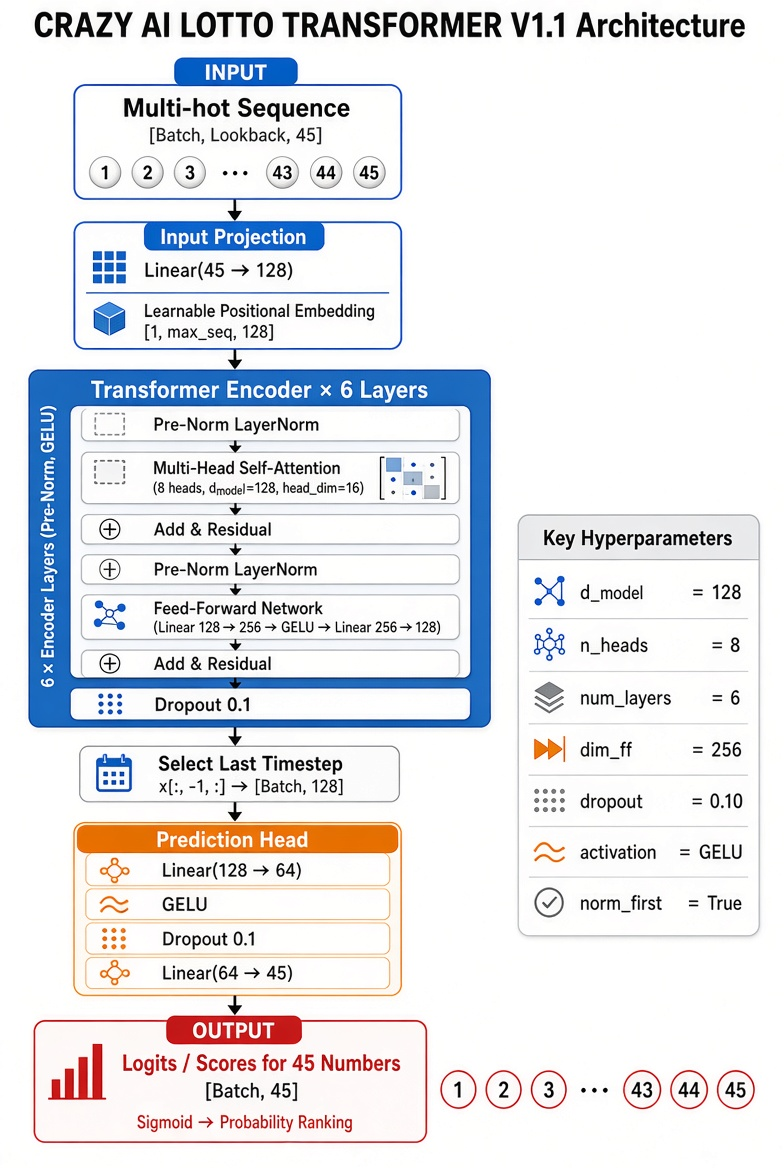